# 02 · Fit archetypes (v2)
Variant tests on the same stability yardstick, then the final fit, naming, and presentation figures (`figs/`).

**Stability:** split players into two halves, fit each, score everyone with both fits, match archetypes, correlate weights. `w_min_avg` = weakest archetype's agreement. Target >= 0.75.
Results checkpoint to `experiments_results.csv`; re-runs skip finished rows.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import archetypes as arch
from scipy.optimize import linear_sum_assignment
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
d = pd.read_pickle("aa_features.pkl")
X_all, raw_all, meta, BASE = d["X"], d["raw"], d["meta"], d["base"]
print(X_all.shape, "| base:", BASE, "| candidates:", d["candidates"]); print(d["config"])
os.makedirs("figs", exist_ok=True); RESULTS = "experiments_results.csv"

def fit_aa(Xv, k, n_init=1, seed=0, max_iter=300):
    sst = float(((Xv - Xv.mean(0)) ** 2).sum())
    for attempt in range(3):
        try:
            return arch.AA(n_archetypes=k, init="furthest_sum", method="nnls", n_init=n_init, max_iter=max_iter,
                           tol=1e-5 * sst, random_state=seed + 1000 * attempt,
                           method_params={"max_iter_optimizer": None}).fit(Xv)
        except RuntimeError as e:
            print(f"  k={k}: {e} -> retry")
    raise RuntimeError(f"AA failed 3x at k={k}")

PRETTY = {"zone_rim": "Rim share", "zone_paint": "Paint share", "zone_baseline2": "Baseline 2 share",
          "zone_elbow2": "Elbow 2 share", "zone_corner3": "Corner 3 share", "zone_wingtop3": "Wing/top 3 share",
          "dunk_of_rim": "Dunks / rim att", "rim_assisted": "Rim assisted %", "mid_assisted": "Midrange assisted %",
          "ab3_assisted": "Above-break 3 assisted %", "unast_pts": "Unassisted pts %", "usage": "Usage %",
          "ast_pct": "Ast %", "oreb_pct": "OReb %", "dreb_pct": "DReb %", "stl_pct": "Stl %", "blk_pct": "Blk %",
          "putback_share": "Putback share", "transition": "Transition share", "long3_share": "Deep 3s / 3PA",
          "ft_rate": "FT rate", "side_lr": "Left-right lean"}

Using NumPy backend
(9907, 22) | base: ['zone_rim', 'zone_paint', 'zone_baseline2', 'zone_elbow2', 'zone_corner3', 'zone_wingtop3', 'dunk_of_rim', 'rim_assisted', 'mid_assisted', 'ab3_assisted', 'unast_pts', 'usage', 'ast_pct', 'oreb_pct', 'dreb_pct', 'stl_pct', 'blk_pct'] | candidates: ['putback_share', 'transition', 'long3_share', 'ft_rate', 'side_lr']
{'DROP_SEASONS': ['2018-19'], 'MPG_FLOOR': 25, 'G_FLOOR': 10, 'WINSOR': 4.0, 'derived_choice': {'ast': 'ast_box', 'blk': 'blk_box', 'dreb': 'dreb_box', 'oreb': 'oreb_box', 'stl': 'stl_box', 'usg': 'usg_box'}}


## Variants
`base` is the EDA-informed set. The candidates test the EDA's claims: does adding a team-context feature (transition, deep 3s) buy stability, or just a non-portable archetype? `group-balanced` rescales so the 6 zone columns don't outvote the 2 rebounding columns.

In [2]:
GROUPS = {"zone": [c for c in BASE if c.startswith("zone_")], "finish": ["dunk_of_rim", "putback_share"],
          "creation": ["rim_assisted", "mid_assisted", "ab3_assisted", "unast_pts", "ft_rate"],
          "role": ["usage", "ast_pct"], "glass": ["oreb_pct", "dreb_pct"], "defense": ["stl_pct", "blk_pct"]}
EXPERIMENTS = {
    "base":                  dict(features=BASE),
    "base - mid_assisted":   dict(features=[c for c in BASE if c != "mid_assisted"]),
    "base - unast_pts":      dict(features=[c for c in BASE if c != "unast_pts"]),
    "base + putback":        dict(features=BASE + ["putback_share"]),
    "base + transition":     dict(features=BASE + ["transition"]),
    "base + long3":          dict(features=BASE + ["long3_share"]),
    "base | group-balanced": dict(features=BASE, strategy="group"),
}
K_LIST = [5, 6, 7]
N_SPLITS = 3

def prepare(spec):
    feats = spec["features"]; Z = X_all[feats].values.astype(float); Xs = Z
    if spec.get("strategy") == "group":
        w = np.ones(len(feats))
        for g, cols in GROUPS.items():
            idx = [i for i, f in enumerate(feats) if f in cols]
            if idx: w[idx] = 1 / np.sqrt(len(idx))
        Xs = Z * w
    return Z, Xs

ids = meta["Player ID"].values; pids = np.unique(ids)
def split_agreement(Xs, k, s, rng):
    half = rng.choice(pids, len(pids) // 2, replace=False); inA = np.isin(ids, half)
    a = fit_aa(Xs[inA], k, n_init=3, seed=10 * s); b = fit_aa(Xs[~inA], k, n_init=3, seed=10 * s + 1)
    Wa, Wb = a.transform(Xs), b.transform(Xs)
    with np.errstate(invalid="ignore", divide="ignore"):
        Cw = np.nan_to_num(np.corrcoef(Wa.T, Wb.T)[:k, k:])
    r, c = linear_sum_assignment(-Cw); return Cw[r, c]

def evr_std(Z, Xs, k):
    m = fit_aa(Xs, k, n_init=2, seed=0); A = m.transform(Xs); Zarch = m.B_ @ Z
    return 1 - ((Z - A @ Zarch) ** 2).sum() / ((Z - Z.mean(0)) ** 2).sum()

In [3]:
res = pd.read_csv(RESULTS) if os.path.exists(RESULTS) else pd.DataFrame()
for name, spec in EXPERIMENTS.items():
    Z, Xs = prepare(spec)
    for k in K_LIST:
        if len(res) and ((res["experiment"] == name) & (res["k"] == k)).any(): continue
        rng = np.random.default_rng(4)
        cs = [split_agreement(Xs, k, s, rng) for s in range(N_SPLITS)]
        row = {"experiment": name, "k": k, "n_feats": len(spec["features"]), "w_mean": np.mean([c.mean() for c in cs]),
               "w_min_avg": np.mean([c.min() for c in cs]), "w_min_worst": np.min([c.min() for c in cs]), "evr": evr_std(Z, Xs, k)}
        res = pd.concat([res, pd.DataFrame([row])], ignore_index=True); res.to_csv(RESULTS, index=False)
        print({kk: (round(float(v), 3) if isinstance(v, float) else v) for kk, v in row.items()})
res = res[res["experiment"].isin(EXPERIMENTS)]
res.pivot(index="experiment", columns="k", values=["w_min_avg", "w_min_worst", "evr"]).round(3)

{'experiment': 'base', 'k': 5, 'n_feats': 17, 'w_mean': 0.692, 'w_min_avg': 0.353, 'w_min_worst': 0.256, 'evr': 0.634}
{'experiment': 'base', 'k': 6, 'n_feats': 17, 'w_mean': 0.674, 'w_min_avg': 0.506, 'w_min_worst': 0.387, 'evr': 0.669}
{'experiment': 'base', 'k': 7, 'n_feats': 17, 'w_mean': 0.637, 'w_min_avg': 0.328, 'w_min_worst': 0.188, 'evr': 0.694}
{'experiment': 'base - mid_assisted', 'k': 5, 'n_feats': 16, 'w_mean': 0.657, 'w_min_avg': 0.264, 'w_min_worst': 0.061, 'evr': 0.654}
{'experiment': 'base - mid_assisted', 'k': 6, 'n_feats': 16, 'w_mean': 0.779, 'w_min_avg': 0.537, 'w_min_worst': 0.155, 'evr': 0.684}
{'experiment': 'base - mid_assisted', 'k': 7, 'n_feats': 16, 'w_mean': 0.825, 'w_min_avg': 0.565, 'w_min_worst': 0.249, 'evr': 0.711}
{'experiment': 'base - unast_pts', 'k': 5, 'n_feats': 16, 'w_mean': 0.706, 'w_min_avg': 0.461, 'w_min_worst': 0.139, 'evr': 0.634}
{'experiment': 'base - unast_pts', 'k': 6, 'n_feats': 16, 'w_mean': 0.736, 'w_min_avg': 0.443, 'w_min_worst': 

w_min_avg               w_min_worst                  evr              
k                             5      6      7           5      6      7      5      6      7
experiment                                                                                  
base                      0.353  0.506  0.328       0.256  0.387  0.188  0.634  0.669  0.694
base + long3              0.339  0.740  0.171      -0.026  0.642 -0.142  0.619  0.645  0.673
base + putback            0.504  0.429  0.319       0.310  0.235  0.025  0.639  0.673  0.701
base + transition         0.561  0.425  0.571       0.417  0.024  0.243  0.613  0.650  0.674
base - mid_assisted       0.264  0.537  0.565       0.061  0.155  0.249  0.654  0.684  0.711
base - unast_pts          0.461  0.443  0.176       0.139  0.103  0.116  0.634  0.666  0.697
base | group-balanced     0.719  0.459  0.326       0.601  0.211 -0.079  0.575  0.607  0.660

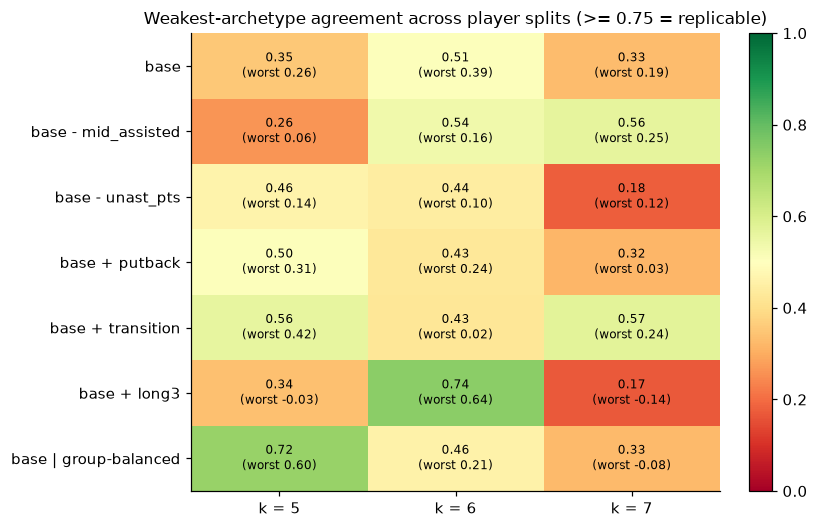

In [4]:
order = list(EXPERIMENTS)
piv = res.pivot(index="experiment", columns="k", values="w_min_avg").reindex(order)
worst = res.pivot(index="experiment", columns="k", values="w_min_worst").reindex(order)
fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(order) + 1.4))
im = ax.imshow(piv.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v, w = piv.iat[i, j], worst.iat[i, j]
        ax.text(j, i, f"{v:.2f}\n(worst {w:.2f})", ha="center", va="center", fontsize=8, fontweight="bold" if v >= .75 else "normal")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"k = {k}" for k in piv.columns])
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_title("Weakest-archetype agreement across player splits (>= 0.75 = replicable)", fontsize=11)
plt.colorbar(im, fraction=.04); plt.tight_layout(); plt.savefig("figs/01_experiment_stability.png", dpi=160, bbox_inches="tight")

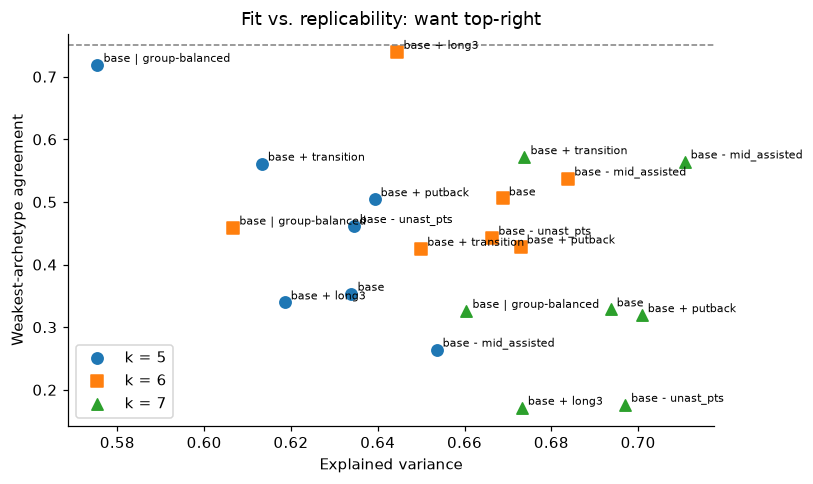

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k, mk in zip(K_LIST, ["o", "s", "^", "D"]):
    sub = res[res["k"] == k]; ax.scatter(sub["evr"], sub["w_min_avg"], marker=mk, s=55, label=f"k = {k}")
    for _, r in sub.iterrows(): ax.annotate(r["experiment"], (r["evr"], r["w_min_avg"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.axhline(.75, ls="--", c="gray", lw=1); ax.set_xlabel("Explained variance"); ax.set_ylabel("Weakest-archetype agreement")
ax.set_title("Fit vs. replicability: want top-right"); ax.legend(); plt.tight_layout(); plt.savefig("figs/02_fit_vs_stability.png", dpi=160, bbox_inches="tight")

## Pick and fit
Largest k with weakest archetype >= 0.75 on average and >= 0.6 in every split; ties by explained variance. Override `BEST`/`K` by hand if needed.

In [6]:
ok = res[(res["w_min_avg"] >= .75) & (res["w_min_worst"] >= .6)]
ranked = ok.sort_values(["k", "evr"], ascending=False) if len(ok) else res.sort_values("w_min_avg", ascending=False)
print("passing setups:" if len(ok) else "nothing passed; most stable:"); print(ranked.round(3).to_string(index=False))
BEST, K = ranked.iloc[0]["experiment"], int(ranked.iloc[0]["k"])
print(f"\n-> BEST = {BEST!r}, K = {K}")

nothing passed; most stable:
           experiment  k  n_feats  w_mean  w_min_avg  w_min_worst   evr
         base + long3  6       18   0.857      0.740        0.642 0.645
base | group-balanced  5       17   0.864      0.719        0.601 0.575
    base + transition  7       18   0.758      0.571        0.243 0.674
  base - mid_assisted  7       16   0.825      0.565        0.249 0.711
    base + transition  5       18   0.782      0.561        0.417 0.613
  base - mid_assisted  6       16   0.779      0.537        0.155 0.684
                 base  6       17   0.674      0.506        0.387 0.669
       base + putback  5       18   0.742      0.504        0.310 0.639
     base - unast_pts  5       16   0.706      0.461        0.139 0.634
base | group-balanced  6       17   0.717      0.459        0.211 0.607
     base - unast_pts  6       16   0.736      0.443        0.103 0.666
       base + putback  6       18   0.716      0.429        0.235 0.673
    base + transition  6       18  

In [7]:
spec = EXPERIMENTS[BEST]; feats = spec["features"]; Z, Xs = prepare(spec)
m = fit_aa(Xs, K, n_init=5, seed=0); W = m.transform(Xs)
Zarch = pd.DataFrame(m.B_ @ Z, columns=feats)
TEMPLATES = {
    "Post Big":          {"oreb_pct": 1, "dreb_pct": 1, "zone_paint": 1, "zone_baseline2": .5, "usage": .5, "dunk_of_rim": -.5},
    "Rim Runner":        {"dunk_of_rim": 1.5, "blk_pct": 1, "rim_assisted": 1, "usage": -.5, "ast_pct": -.5},
    "Lead Creator":      {"unast_pts": 1, "ab3_assisted": -1, "usage": 1, "ast_pct": 1},
    "Pull-up Guard":     {"zone_elbow2": 1.5, "mid_assisted": -1, "unast_pts": .5},
    "Spot-up Spacer":    {"zone_corner3": 1.5, "ab3_assisted": .5, "usage": -.5},
    "Movement Shooter":  {"zone_wingtop3": 1.5, "ab3_assisted": .5, "zone_corner3": -.5},
    "Disruptor":         {"stl_pct": 1.5, "usage": -.3},
    "Slasher":           {"zone_rim": 1, "rim_assisted": -1, "dunk_of_rim": -.5, "unast_pts": .5, "oreb_pct": -.5},
    "Stretch Big":       {"oreb_pct": .5, "dreb_pct": .5, "blk_pct": .5, "zone_wingtop3": .5, "zone_corner3": .5},
}
S = np.array([[sum(wt * Zarch.at[i, f] for f, wt in t.items() if f in feats) for t in TEMPLATES.values()] for i in range(K)])
r, c = linear_sum_assignment(-S); NAMES = [list(TEMPLATES)[c[list(r).index(i)]] for i in range(K)]
# NAMES = [...]   # <- override by hand after checking exemplars
Zarch.index = NAMES; Wdf = pd.DataFrame(W, index=X_all.index, columns=NAMES)
for n in NAMES:
    top = Zarch.loc[n].sort_values(key=abs, ascending=False).head(5)
    print(f"{n:18s} " + ", ".join(f"{PRETTY.get(f, f)} {v:+.1f}" for f, v in top.items()))

Spot-up Spacer     Rim share -2.3, Paint share -2.3, Unassisted pts % -2.1, Corner 3 share +1.7, OReb % -1.7
Pull-up Guard      Ast % +2.3, Unassisted pts % +2.3, Wing/top 3 share -1.7, Midrange assisted % -1.7, Stl % +1.7
Rim Runner         Rim share +3.0, Paint share +2.9, Blk % +2.3, Wing/top 3 share -2.2, OReb % +2.0
Post Big           Midrange assisted % +3.7, Corner 3 share -2.7, Baseline 2 share +2.7, DReb % +2.6, Wing/top 3 share -2.4
Stretch Big        Baseline 2 share -2.8, Elbow 2 share -2.4, Corner 3 share +2.1, Unassisted pts % -1.7, Wing/top 3 share +1.7
Lead Creator       Deep 3s / 3PA +3.4, Above-break 3 assisted % -3.0, Usage % +2.3, Unassisted pts % +1.7, Rim assisted % -1.6


## Figures

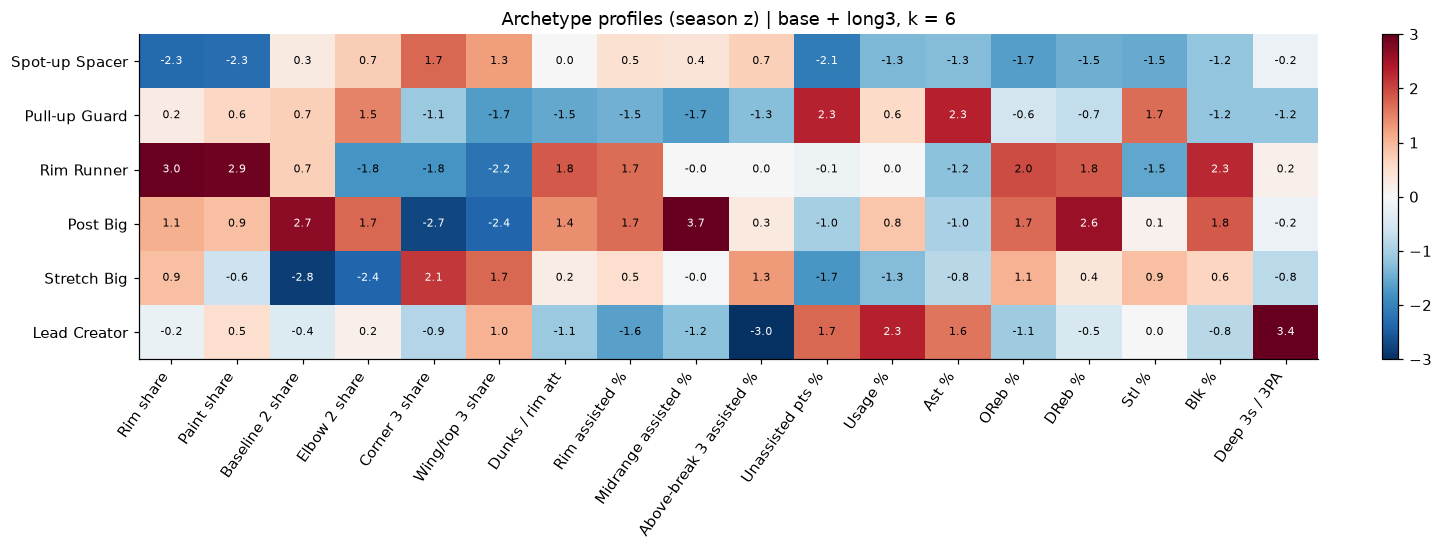

In [8]:
cols = Zarch.columns
fig, ax = plt.subplots(figsize=(0.6 * len(cols) + 2.5, 0.55 * K + 1.8))
im = ax.imshow(Zarch.values, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
for i in range(K):
    for j in range(len(cols)):
        v = Zarch.iat[i, j]; ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 2 else "black")
ax.set_xticks(range(len(cols))); ax.set_xticklabels([PRETTY.get(c, c) for c in cols], rotation=55, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(NAMES); ax.set_title(f"Archetype profiles (season z) | {BEST}, k = {K}")
plt.colorbar(im, fraction=.025); plt.tight_layout(); plt.savefig("figs/03_archetype_profiles.png", dpi=160, bbox_inches="tight")

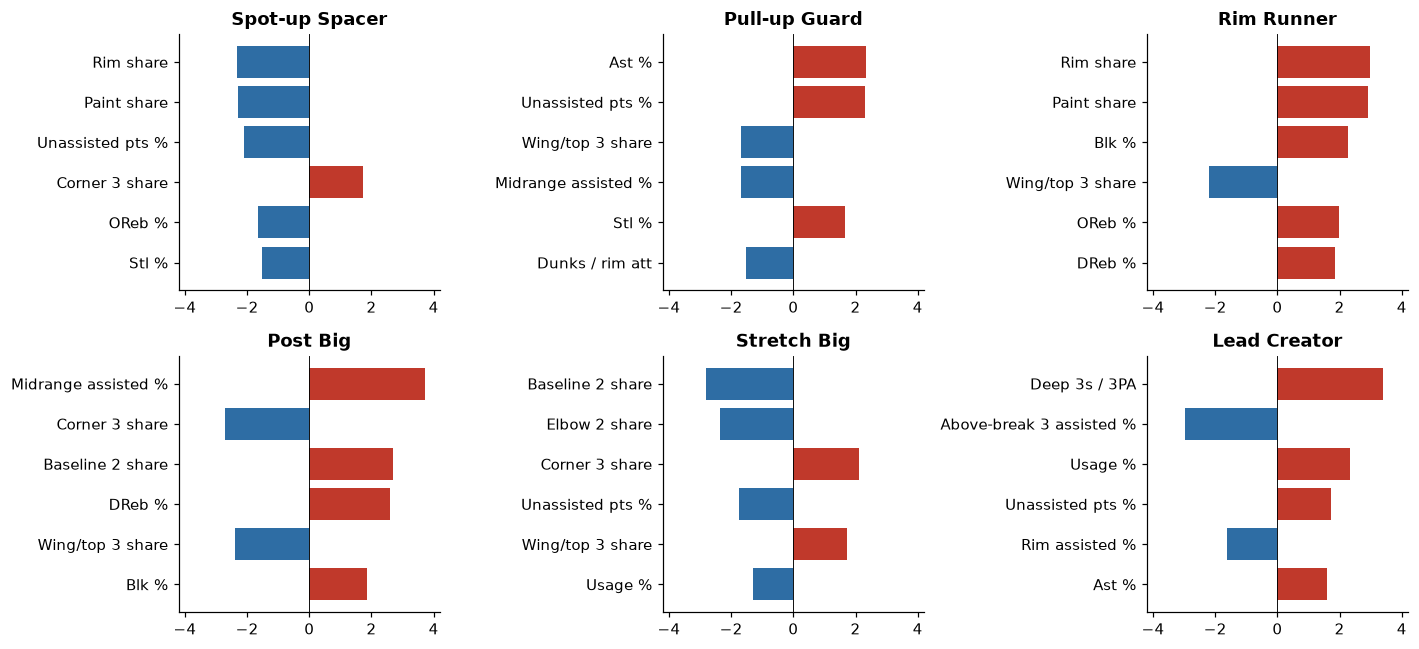

In [9]:
ncol = 3; nrow = int(np.ceil(K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3 * nrow))
for ax, n in zip(axes.flat, NAMES):
    top = Zarch.loc[n].sort_values(key=abs, ascending=False).head(6)[::-1]
    ax.barh([PRETTY.get(f, f) for f in top.index], top.values, color=["#c0392b" if v > 0 else "#2e6da4" for v in top.values])
    ax.axvline(0, c="k", lw=.6); ax.set_xlim(-4.2, 4.2); ax.set_title(n, fontweight="bold")
for ax in axes.flat[K:]: ax.axis("off")
plt.tight_layout(); plt.savefig("figs/04_archetype_signatures.png", dpi=160, bbox_inches="tight")

In [10]:
show = [c for c in ["Player", "Team", "Season", "Pos", "Height (in)", "Min/G"] if c in meta]
ex = []
for n in NAMES:
    top = Wdf[n].sort_values(ascending=False).head(6).index
    t = meta.loc[top, show].assign(archetype=n, weight=Wdf.loc[top, n].round(2)); ex.append(t)
    print(f"\n== {n}  (median ht of w>=.6: {meta.loc[Wdf[n] >= .6, 'Height (in)'].median()})"); print(t.drop(columns="archetype").to_string(index=False))
pd.concat(ex).to_csv("figs/exemplars.csv", index=False)


== Spot-up Spacer  (median ht of w>=.6: 76.0)
             Player             Team  Season Pos  Height (in)  Min/G  weight
    Tyler Patterson      Montana St. 2023-24   G         80.0   36.0    0.98
      Cole Anderson UC Santa Barbara 2023-24   G         77.0   32.1    0.97
William FitzPatrick   Sacramento St. 2020-21   G         75.0   35.9    0.95
        Chris Ashby      Queens (NC) 2023-24   G         74.0   27.2    0.92
    Alem Huseinovic             Rice 2024-25   G         76.0   25.6    0.91
     Marquis Godwin          Hampton 2022-23   G         77.0   34.7    0.90

== Pull-up Guard  (median ht of w>=.6: 74.0)
             Player             Team  Season Pos  Height (in)  Min/G  weight
         Adam Clark        Merrimack 2023-24   G         70.0   31.3    1.00
   Jeremiah Quigley       Binghamton 2025-26   G         71.0   37.4    0.92
Pierre Crockrell II        UC Irvine 2023-24   G         72.0   26.7    0.90
     Blaise Threatt        Weber St. 2024-25   G         75.

top-archetype share by season (should be flat):
col_0    Lead Creator  Post Big  Pull-up Guard  Rim Runner  Spot-up Spacer  Stretch Big
Season                                                                                 
2019-20         0.135     0.091          0.188       0.114           0.296        0.176
2020-21         0.134     0.095          0.203       0.098           0.276        0.194
2021-22         0.130     0.084          0.214       0.099           0.271        0.203
2022-23         0.147     0.079          0.194       0.105           0.279        0.195
2023-24         0.152     0.076          0.197       0.107           0.270        0.198
2024-25         0.137     0.068          0.202       0.118           0.275        0.200
2025-26         0.127     0.068          0.207       0.120           0.278        0.200


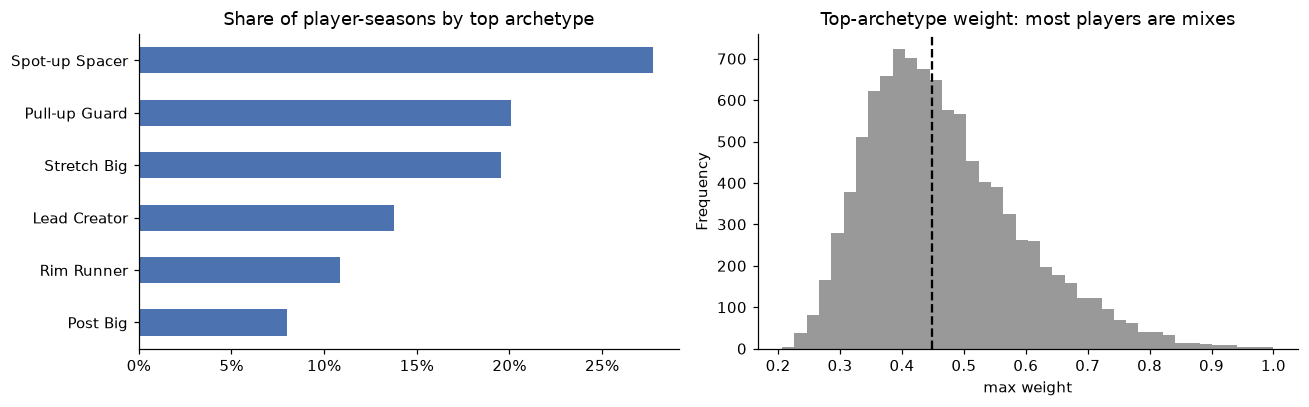

In [11]:
dom = Wdf.idxmax(axis=1).value_counts(normalize=True).reindex(NAMES)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
dom.sort_values().plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Share of player-seasons by top archetype")
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
Wdf.max(axis=1).plot.hist(bins=40, ax=ax[1], color="#999"); ax[1].set_title("Top-archetype weight: most players are mixes")
ax[1].axvline(Wdf.max(axis=1).median(), c="k", ls="--"); ax[1].set_xlabel("max weight")
plt.tight_layout(); plt.savefig("figs/05_mix_and_purity.png", dpi=160, bbox_inches="tight")
print("top-archetype share by season (should be flat):"); print(pd.crosstab(meta["Season"], Wdf.idxmax(axis=1), normalize="index").round(3))

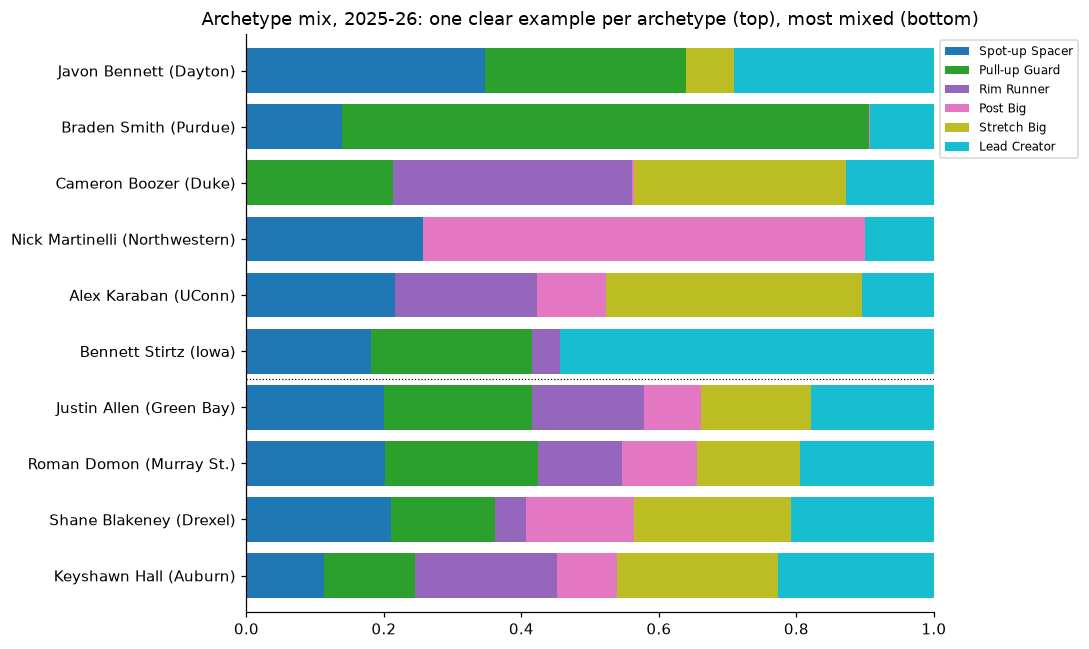

In [12]:
latest = meta["Season"].max(); cur = Wdf[meta["Season"] == latest]; top = cur.idxmax(axis=1)
pick = [meta.loc[top[top == n].index, "Min"].idxmax() for n in NAMES if (top == n).any()]
pick += list(cur.drop(index=pick).max(axis=1).nsmallest(4).index)
mix = Wdf.loc[pick]; mix.index = (meta.loc[pick, "Player"] + " (" + meta.loc[pick, "Team"] + ")").values
ax = mix.iloc[::-1].plot.barh(stacked=True, figsize=(10, 0.45 * len(mix) + 1.5), width=.8, colormap="tab10")
ax.axhline(3.5, c="k", lw=.8, ls=":"); ax.set_xlim(0, 1)
ax.set_title(f"Archetype mix, {latest}: one clear example per archetype (top), most mixed (bottom)"); ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig("figs/06_example_mixes.png", dpi=160, bbox_inches="tight")

                n  cosine  same_top
group                              
Same team    2932   0.888     0.639
Transferred  1445   0.831     0.526


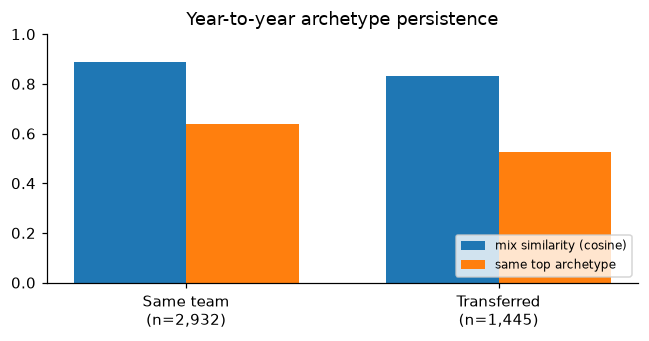

In [13]:
mm = meta[["Player ID", "Season", "Team ID"]].join(Wdf).sort_values(["Player ID", "Season"])
nxt = mm.groupby("Player ID").shift(-1); pair = nxt["Season"].notna()
w0, w1 = mm.loc[pair, NAMES].values, nxt.loc[pair, NAMES].values.astype(float)
cos = (w0 * w1).sum(1) / (np.linalg.norm(w0, axis=1) * np.linalg.norm(w1, axis=1))
moved = mm.loc[pair, "Team ID"].values != nxt.loc[pair, "Team ID"].values
pers = (pd.DataFrame({"group": np.where(moved, "Transferred", "Same team"), "cosine": cos, "same_top": w0.argmax(1) == w1.argmax(1)})
        .groupby("group").agg(n=("cosine", "size"), cosine=("cosine", "mean"), same_top=("same_top", "mean")))
print(pers.round(3))
fig, ax = plt.subplots(figsize=(6, 3.2)); x = np.arange(2)
ax.bar(x - .18, pers["cosine"], .36, label="mix similarity (cosine)"); ax.bar(x + .18, pers["same_top"], .36, label="same top archetype")
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n(n={n:,})" for g, n in zip(pers.index, pers["n"])]); ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Year-to-year archetype persistence")
plt.tight_layout(); plt.savefig("figs/07_transfer_persistence.png", dpi=160, bbox_inches="tight")

In [14]:
import pickle
Wdf.join(meta).to_pickle(f"aa_weights_k{K}.pkl")
with open(f"aa_model_k{K}.pkl", "wb") as f:
    pickle.dump({"model": m, "features": feats, "strategy": spec.get("strategy"), "names": NAMES, "config": d["config"]}, f)
Zarch.round(2).to_csv("figs/archetype_profiles.csv"); res.round(3).to_csv("figs/experiment_results.csv", index=False)
print("BEST:", BEST, "K:", K, "| features:", feats)
print("\n" + res.pivot(index="experiment", columns="k", values=["w_min_avg", "w_min_worst", "evr"]).round(3).to_string())
print("\nprofiles:"); print(Zarch.round(1).to_string())
print("\ntop-archetype share:", dom.round(3).to_dict()); print("median max weight:", round(Wdf.max(axis=1).median(), 3))
print("\npersistence:"); print(pers.round(3).to_string()); print("\nfigs/:", sorted(os.listdir("figs")))

BEST: base + long3 K: 6 | features: ['zone_rim', 'zone_paint', 'zone_baseline2', 'zone_elbow2', 'zone_corner3', 'zone_wingtop3', 'dunk_of_rim', 'rim_assisted', 'mid_assisted', 'ab3_assisted', 'unast_pts', 'usage', 'ast_pct', 'oreb_pct', 'dreb_pct', 'stl_pct', 'blk_pct', 'long3_share']

                      w_min_avg               w_min_worst                  evr              
k                             5      6      7           5      6      7      5      6      7
experiment                                                                                  
base                      0.353  0.506  0.328       0.256  0.387  0.188  0.634  0.669  0.694
base + long3              0.339  0.740  0.171      -0.026  0.642 -0.142  0.619  0.645  0.673
base + putback            0.504  0.429  0.319       0.310  0.235  0.025  0.639  0.673  0.701
base + transition         0.561  0.425  0.571       0.417  0.024  0.243  0.613  0.650  0.674
base - mid_assisted       0.264  0.537  0.565       0.061  0.1